I. Pour les mesures de qualités

I. 1. Chargement des données

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Charger les données
data = pd.read_csv("/content/drive/MyDrive/program-measures.csv")

print(data.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Group       12 non-null     int64
 1   Project ID  12 non-null     int64
 2   MI          12 non-null     int64
 3   CC          12 non-null     int64
 4   DIT         12 non-null     int64
 5   CBO         12 non-null     int64
 6   NLoC        12 non-null     int64
 7   NLoCExec    12 non-null     int64
dtypes: int64(8)
memory usage: 896.0 bytes
None


I. 2. Statistiques de base globales


In [3]:
# Analyse descriptive
print("\nAnalyse descriptive :")
print(data.describe())



Analyse descriptive :
           Group  Project ID        MI        CC   DIT      CBO        NLoC  \
count  12.000000   12.000000  12.00000  12.00000  12.0  12.0000   12.000000   
mean    0.500000    3.000000  92.75000  68.25000   1.0  25.5000  361.333333   
std     0.522233    2.088932   1.05529  13.44433   0.0   0.6742   56.138357   
min     0.000000    0.000000  91.00000  48.00000   1.0  25.0000  276.000000   
25%     0.000000    1.750000  92.00000  59.75000   1.0  25.0000  337.000000   
50%     0.500000    3.000000  93.00000  64.50000   1.0  25.0000  357.000000   
75%     1.000000    4.250000  93.00000  74.50000   1.0  26.0000  375.000000   
max     1.000000    6.000000  95.00000  99.00000   1.0  27.0000  513.000000   

         NLoCExec  
count   12.000000  
mean    97.416667  
std     26.503716  
min     59.000000  
25%     85.500000  
50%     94.000000  
75%    103.250000  
max    170.000000  


3. Matrice de corrélation

In [ ]:
# Corrélation de Pearson
print("\nMatrice de corrélation (Pearson) :")
print(data.corr())



Matrice de corrélation (Pearson) :
               Group  Project ID        MI        CC  DIT       CBO      NLoC  \
Group       1.000000    0.166667  0.742307 -0.718616  NaN -0.258199 -0.474433   
Project ID  0.166667    1.000000 -0.123718  0.106821  NaN  0.129099  0.132562   
MI          0.742307   -0.123718  1.000000 -0.924299  NaN -0.574989 -0.842458   
CC         -0.718616    0.106821 -0.924299  1.000000  NaN  0.747198  0.928914   
DIT              NaN         NaN       NaN       NaN  NaN       NaN       NaN   
CBO        -0.258199    0.129099 -0.574989  0.747198  NaN  1.000000  0.771017   
NLoC       -0.474433    0.132562 -0.842458  0.928914  NaN  0.771017  1.000000   
NLoCExec   -0.515592    0.108373 -0.847526  0.938559  NaN  0.735156  0.981469   

            NLoCExec  
Group      -0.515592  
Project ID  0.108373  
MI         -0.847526  
CC          0.938559  
DIT              NaN  
CBO         0.735156  
NLoC        0.981469  
NLoCExec    1.000000  



Visualisation de la matrice de corrélation :


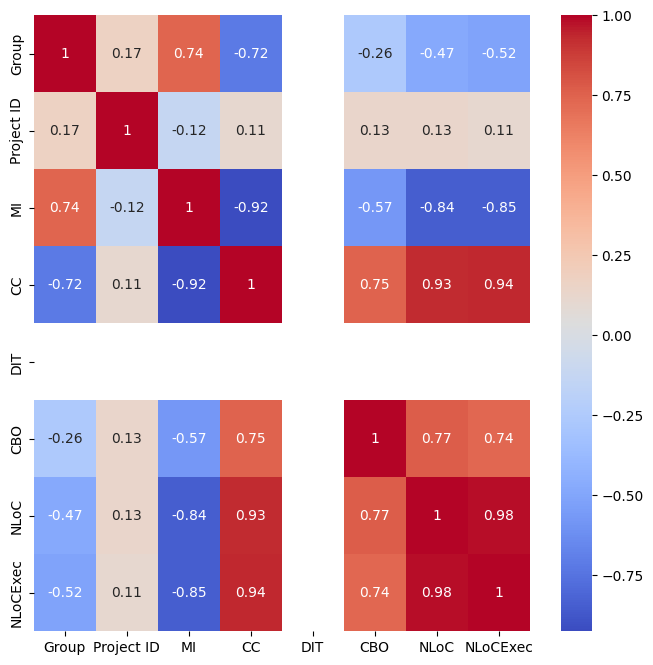

In [ ]:
# Diagramme de corrélation
plt.figure(figsize=(8, 8))
print("\nVisualisation de la matrice de corrélation :")
sns.heatmap(data.corr(), annot=True, cmap='coolwarm')
plt.show()

I. 4. Visualisation par des histogrammes

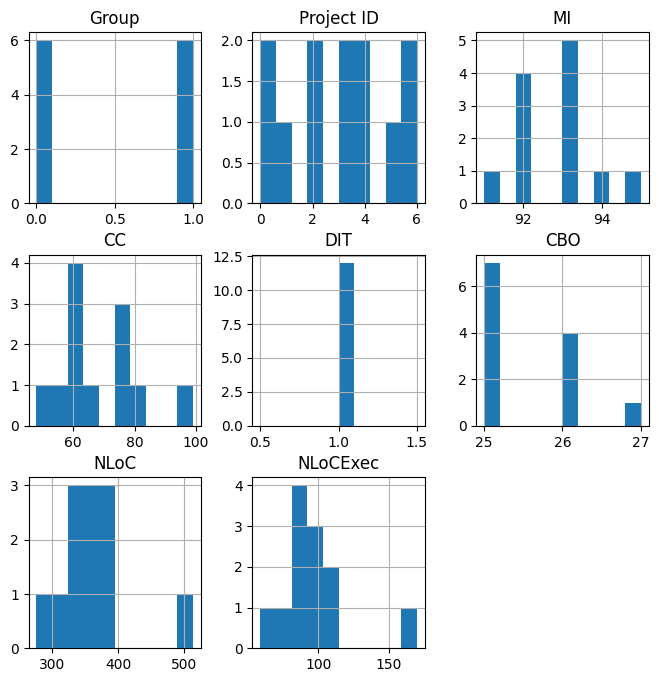

In [26]:
# Histogrammes
data.hist(bins=10, figsize=(8, 8))
plt.show()

I. 5. Test de normalité de Shapiro Wilk

In [ ]:
from scipy.stats import shapiro

# Test de Shapiro-Wilk pour chaque colonne
for column in data.columns:
    if data[column].dtype != 'object': # Ignorer les colonnes non numériques
        stat, p = shapiro(data[column])
        print("\nTest de normalité pour :")
        print(f"{column}: stat={stat}, p={p}")
        if p > 0.05:
            print(f"{column} est normalement distribuée.")
        else:
            print(f"{column} n'est pas normalement distribuée.")



Test de normalité pour :
Group: stat=0.6497829556465149, p=0.00028840036247856915
Group n'est pas normalement distribuée.

Test de normalité pour :
Project ID: stat=0.9410193562507629, p=0.5113899111747742
Project ID est normalement distribuée.

Test de normalité pour :
MI: stat=0.9110451340675354, p=0.2200276106595993
MI est normalement distribuée.

Test de normalité pour :
CC: stat=0.9330852031707764, p=0.41396358609199524
CC est normalement distribuée.

Test de normalité pour :
DIT: stat=1.0, p=1.0
DIT est normalement distribuée.

Test de normalité pour :
CBO: stat=0.7321119904518127, p=0.0017493532504886389
CBO n'est pas normalement distribuée.

Test de normalité pour :
NLoC: stat=0.8227782845497131, p=0.017210330814123154
NLoC n'est pas normalement distribuée.

Test de normalité pour :
NLoCExec: stat=0.8059190511703491, p=0.01094786822795868
NLoCExec n'est pas normalement distribuée.


/usr/local/lib/python3.10/dist-packages/scipy/stats/_morestats.py:1879: UserWarning: Input data for shapiro has range zero. The results may not be accurate.
  warnings.warn("Input data for shapiro has range zero. The results "


I. 6. Visualisation de la distribution par des histogrammes

Test de normalité pour MI:
Statistique: 0.9110451340675354, p-value: 0.2200276106595993
La distribution est normale.


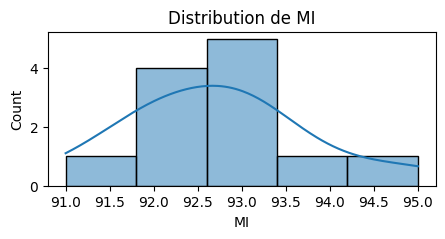

Test de normalité pour CC:
Statistique: 0.9330852031707764, p-value: 0.41396358609199524
La distribution est normale.


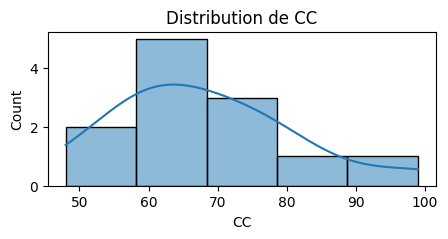

Test de normalité pour DIT:
Statistique: 1.0, p-value: 1.0
La distribution est normale.


/usr/local/lib/python3.10/dist-packages/scipy/stats/_morestats.py:1879: UserWarning: Input data for shapiro has range zero. The results may not be accurate.
  warnings.warn("Input data for shapiro has range zero. The results "


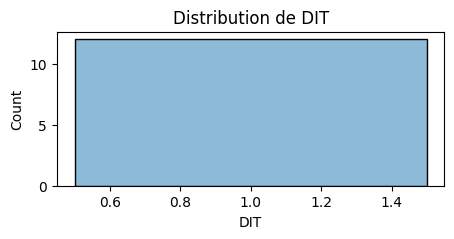

Test de normalité pour CBO:
Statistique: 0.7321119904518127, p-value: 0.0017493532504886389
La distribution n'est pas normale.


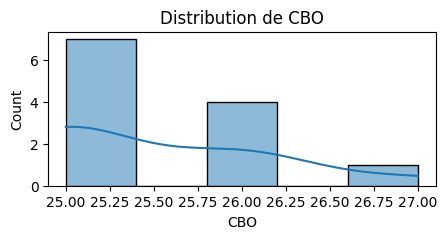

Test de normalité pour NLoC:
Statistique: 0.8227782845497131, p-value: 0.017210330814123154
La distribution n'est pas normale.


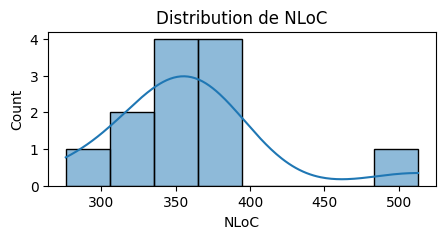

Test de normalité pour NLoCExec:
Statistique: 0.8059190511703491, p-value: 0.01094786822795868
La distribution n'est pas normale.


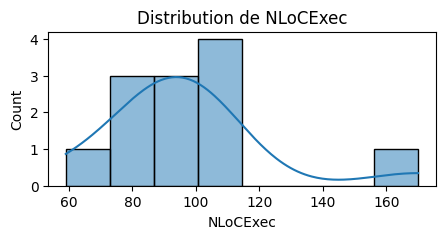

In [ ]:
from scipy import stats
# Test de normalité pour chaque variable
for column in data.columns:
    if column not in ['Group', 'Project ID']:
        print(f"Test de normalité pour {column}:")
        stat, p = stats.shapiro(data[column])
        print(f"Statistique: {stat}, p-value: {p}")
        if p > 0.05:
            print("La distribution est normale.")
        else:
            print("La distribution n'est pas normale.")
        plt.figure(figsize=(5, 2))
        sns.histplot(data[column], kde=True)
        plt.title(f"Distribution de {column}")
        plt.show()


I. 7. Visualisation par des box plots

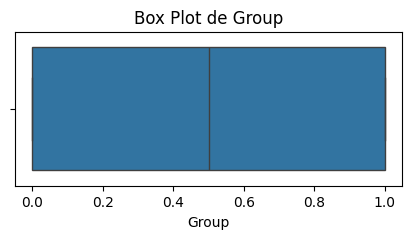

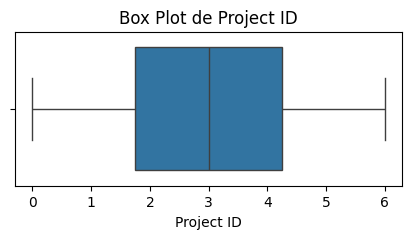

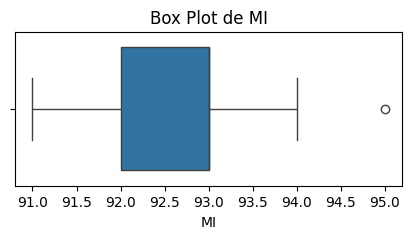

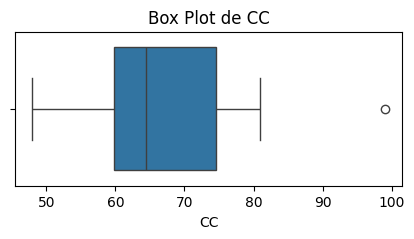

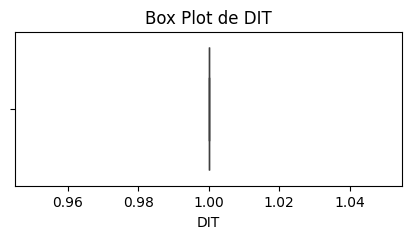

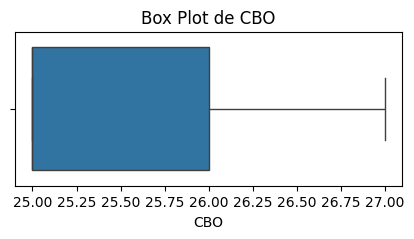

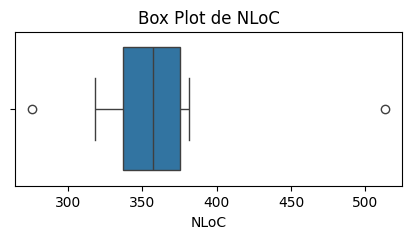

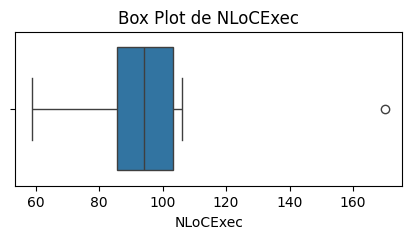

In [ ]:
# Box Plots
for column in data.columns:
    plt.figure(figsize=(5, 2))
    sns.boxplot(x=data[column])
    plt.title(f"Box Plot de {column}")
    plt.show()


In [ ]:
# Analyse statistique pour chaque variable
for column in data.columns:
    if column != 'Group':
        print(f"Analyse statistique pour {column}:")
        if stats.shapiro(data[column])[1] > 0.05: # Si la distribution est normale
            t_stat, p_value = stats.ttest_ind(data[data['Group'] == 0][column], data[data['Group'] == 1][column])
            print(f"Test de Student: Statistique t = {t_stat}, p-value = {p_value}")
        else: # Si la distribution n'est pas normale
            u_stat, p_value = stats.mannwhitneyu(data[data['Group'] == 0][column], data[data['Group'] == 1][column])
            print(f"Test de Mann-Whitney: Statistique U = {u_stat}, p-value = {p_value}")


Analyse statistique pour Project ID:
Test de Student: Statistique t = -0.534522483824849, p-value = 0.6046599442533788
Analyse statistique pour MI:
Test de Student: Statistique t = -3.503245248726853, p-value = 0.005695544447391016
Analyse statistique pour CC:
Test de Student: Statistique t = 3.2678168775324306, p-value = 0.008461489058500608
Analyse statistique pour DIT:
Test de Student: Statistique t = nan, p-value = nan
Analyse statistique pour CBO:
Test de Mann-Whitney: Statistique U = 22.0, p-value = 0.5228166539190886
Analyse statistique pour NLoC:
Test de Mann-Whitney: Statistique U = 30.0, p-value = 0.06508095865779158
Analyse statistique pour NLoCExec:
Test de Mann-Whitney: Statistique U = 31.0, p-value = 0.04112554112554113


/usr/local/lib/python3.10/dist-packages/scipy/stats/_morestats.py:1879: UserWarning: Input data for shapiro has range zero. The results may not be accurate.
  warnings.warn("Input data for shapiro has range zero. The results "


I. 8. Tests Statistiques appropriés : Test t de Student et test de Mann-Whitney

In [ ]:
from scipy.stats import ttest_ind, mannwhitneyu

# Séparer les données par groupe
group_0 = data[data['Group'] == 0]
group_1 = data[data['Group'] == 1]

# Test de t de Student pour "MI", "CC", "DIT"
for column in ['MI', 'CC', 'DIT']:
    stat, p = ttest_ind(group_0[column], group_1[column])
    print("\nTest statistique t de Student pour :")
    print(f"{column} : stat={stat}, p={p}")
    if p < 0.05:
        print(f"Il y a une différence significative entre les groupes pour {column}.")
    else:
        print(f"Il n'y a pas de différence significative entre les groupes pour {column}.")

# Test de Mann-Whitney pour "CBO", "NLoC", "NLoCExec"
for column in ['CBO', 'NLoC', 'NLoCExec']:
    stat, p = mannwhitneyu(group_0[column], group_1[column])
    print("\nTest statistique de Mann-Whitney pour :")
    print(f"{column} : stat={stat}, p={p}")
    if p < 0.05:
        print(f"Il y a une différence significative entre les groupes pour {column}.")
    else:
        print(f"Il n'y a pas de différence significative entre les groupes pour {column}.")



Test statistique t de Student pour :
MI : stat=-3.503245248726853, p=0.005695544447391016
Il y a une différence significative entre les groupes pour MI.

Test statistique t de Student pour :
CC : stat=3.2678168775324306, p=0.008461489058500608
Il y a une différence significative entre les groupes pour CC.

Test statistique t de Student pour :
DIT : stat=nan, p=nan
Il n'y a pas de différence significative entre les groupes pour DIT.

Test statistique de Mann-Whitney pour :
CBO : stat=22.0, p=0.5228166539190886
Il n'y a pas de différence significative entre les groupes pour CBO.

Test statistique de Mann-Whitney pour :
NLoC : stat=30.0, p=0.06508095865779158
Il n'y a pas de différence significative entre les groupes pour NLoC.

Test statistique de Mann-Whitney pour :
NLoCExec : stat=31.0, p=0.04112554112554113
Il y a une différence significative entre les groupes pour NLoCExec.


I. 9. Statistiques de base pour chaque groupe

In [ ]:
group_0 = data[data['Group'] == 0]
group_1 = data[data['Group'] == 1]

# Analyse descriptive pour le groupe 0
print("Analyse descriptive pour le groupe 0 :")
print(group_0.describe())

Analyse descriptive pour le groupe 0 :
       Group  Project ID         MI         CC  DIT        CBO        NLoC  \
count    6.0    6.000000   6.000000   6.000000  6.0   6.000000    6.000000   
mean     0.0    2.666667  92.000000  77.500000  1.0  25.666667  386.833333   
std      0.0    2.160247   0.632456  12.437845  0.0   0.816497   65.946696   
min      0.0    0.000000  91.000000  61.000000  1.0  25.000000  318.000000   
25%      0.0    1.250000  92.000000  74.000000  1.0  25.000000  363.000000   
50%      0.0    2.500000  92.000000  75.000000  1.0  25.500000  375.000000   
75%      0.0    3.750000  92.000000  79.750000  1.0  26.000000  379.500000   
max      0.0    6.000000  93.000000  99.000000  1.0  27.000000  513.000000   

         NLoCExec  
count    6.000000  
mean   110.500000  
std     30.943497  
min     78.000000  
25%    102.250000  
50%    103.500000  
75%    105.500000  
max    170.000000  


In [ ]:
# Analyse descriptive pour le groupe 1
print("\nAnalyse descriptive pour le groupe 1 :")
print(group_1.describe())


Analyse descriptive pour le groupe 1 :
       Group  Project ID        MI         CC  DIT        CBO        NLoC  \
count    6.0    6.000000   6.00000   6.000000  6.0   6.000000    6.000000   
mean     1.0    3.333333  93.50000  59.000000  1.0  25.333333  335.833333   
std      0.0    2.160247   0.83666   6.131884  0.0   0.516398   31.996354   
min      1.0    0.000000  93.00000  48.000000  1.0  25.000000  276.000000   
25%      1.0    2.250000  93.00000  58.250000  1.0  25.000000  333.000000   
50%      1.0    3.500000  93.00000  59.500000  1.0  25.000000  342.500000   
75%      1.0    4.750000  93.75000  62.250000  1.0  25.750000  352.750000   
max      1.0    6.000000  95.00000  66.000000  1.0  26.000000  368.000000   

        NLoCExec  
count   6.000000  
mean   84.333333  
std    13.306640  
min    59.000000  
25%    84.500000  
50%    87.500000  
75%    89.750000  
max    98.000000  


# New Section
II. Pour le sondage


II. 1. Chargement des données

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Charger les données
data = pd.read_csv("/content/drive/MyDrive/survey-data.csv")

print(data.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   group            10 non-null     int64
 1   workload         10 non-null     int64
 2   difficulty       10 non-null     int64
 3   complexity       10 non-null     int64
 4   mental.demand    10 non-null     int64
 5   physical.demand  10 non-null     int64
 6   temporal.demand  10 non-null     int64
 7   performance      10 non-null     int64
 8   effort           10 non-null     int64
 9   frustration      10 non-null     int64
dtypes: int64(10)
memory usage: 928.0 bytes
None


II. 2. Statistiques de base globales

In [6]:
# Analyse descriptive
print("\nAnalyse descriptive:")
print(data.describe())


Analyse descriptive:
           group   workload  difficulty  complexity  mental.demand  \
count  10.000000  10.000000   10.000000   10.000000      10.000000   
mean    0.500000   3.600000    3.200000    2.700000       5.700000   
std     0.527046   0.699206    0.918937    0.823273       1.251666   
min     0.000000   3.000000    2.000000    2.000000       4.000000   
25%     0.000000   3.000000    2.250000    2.000000       4.500000   
50%     0.500000   3.500000    3.500000    2.500000       6.000000   
75%     1.000000   4.000000    4.000000    3.000000       6.750000   
max     1.000000   5.000000    4.000000    4.000000       7.000000   

       physical.demand  temporal.demand  performance     effort  frustration  
count        10.000000        10.000000    10.000000  10.000000    10.000000  
mean          4.000000         5.000000     5.400000   5.300000     5.300000  
std           2.260777         2.054805     2.065591   1.636392     2.213594  
min           1.000000         

II. 3. Matrice de corrélation

In [3]:
# Corrélation de Pearson
print("\nMatrice de corrélation (Pearson) :")
print(data.corr())



Matrice de corrélation (Pearson) :
                        group  workload    difficulty  complexity  \
group            1.000000e+00 -0.301511 -3.629512e-16   -0.640184   
workload        -3.015113e-01  1.000000  1.383429e-01    0.347441   
difficulty      -3.629512e-16  0.138343  1.000000e+00    0.381858   
complexity      -6.401844e-01  0.347441  3.818578e-01    1.000000   
mental.demand    2.526456e-01  0.101567  5.796087e-02    0.226436   
physical.demand  1.865010e-01  0.070290 -1.604485e-01   -0.119395   
temporal.demand -2.051957e-01  0.077336  3.530634e-01    0.328408   
performance      1.020621e-01 -0.415434 -2.224391e-01   -0.248286   
effort           3.220783e-01  0.116532  3.990051e-01    0.321656   
frustration      1.428571e-01  0.229723  1.310947e-01    0.237783   

                 mental.demand  physical.demand  temporal.demand  performance  \
group                 0.252646         0.186501        -0.205196     0.102062   
workload              0.101567         0.0


Visualisation de la Matrice de corrélation (Pearson) :


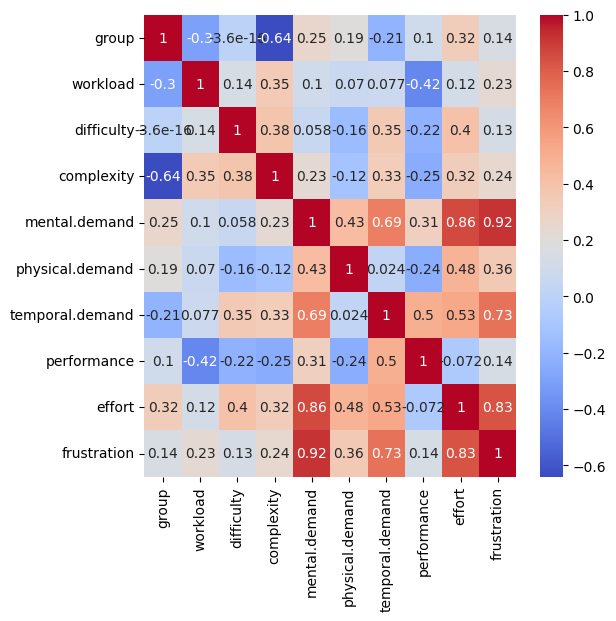

In [33]:
# Diagramme de corrélation
plt.figure(figsize=(6, 6))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm')
print("\nVisualisation de la Matrice de corrélation (Pearson) :")
plt.show()


II. 4. Visualisation par des histogrammes


Visualisation par des histogrammes :


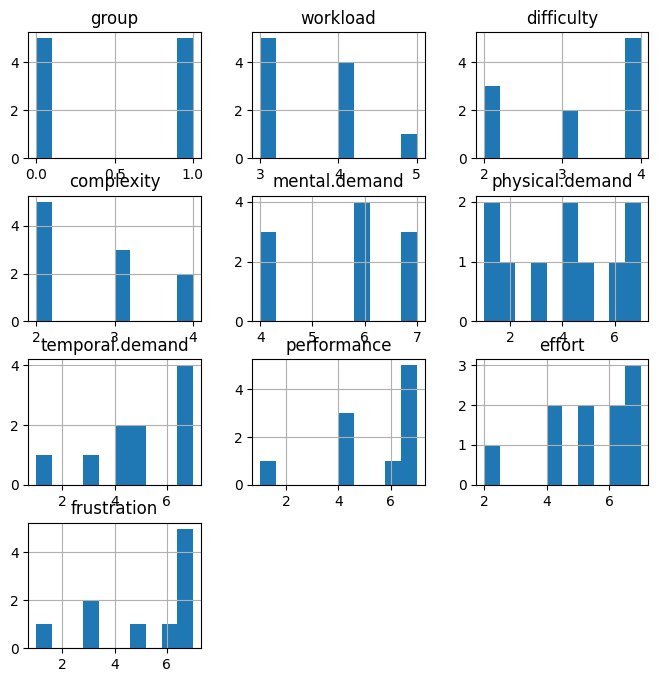

In [23]:
# Histogrammes
data.hist(bins=10, figsize=(8, 8))
print("\nVisualisation par des histogrammes :")
plt.show()

II. 5. Test de normalité de Shapiro Wilk

In [ ]:
from scipy.stats import shapiro

# Test de Shapiro-Wilk pour chaque colonne
for column in data.columns:
    if data[column].dtype != 'object': # Ignorer les colonnes non numériques
        stat, p = shapiro(data[column])
        print("\nTest de normalité pour :")
        print(f"{column}: stat={stat}, p={p}")
        if p > 0.05:
            print(f"{column} est normalement distribuée.")
        else:
            print(f"{column} n'est pas normalement distribuée.")



Test de normalité pour :
group: stat=0.6552711725234985, p=0.00025396436103619635
group n'est pas normalement distribuée.

Test de normalité pour :
workload: stat=0.7808946967124939, p=0.00848899781703949
workload n'est pas normalement distribuée.

Test de normalité pour :
difficulty: stat=0.7559678554534912, p=0.0042188530787825584
difficulty n'est pas normalement distribuée.

Test de normalité pour :
complexity: stat=0.780940055847168, p=0.00849983375519514
complexity n'est pas normalement distribuée.

Test de normalité pour :
mental.demand: stat=0.7964456081390381, p=0.013125520199537277
mental.demand n'est pas normalement distribuée.

Test de normalité pour :
physical.demand: stat=0.9238799810409546, p=0.39045506715774536
physical.demand est normalement distribuée.

Test de normalité pour :
temporal.demand: stat=0.8760036826133728, p=0.1173669621348381
temporal.demand est normalement distribuée.

Test de normalité pour :
performance: stat=0.782243013381958, p=0.00881610531359911
p

II. 6. Visualisation de la distribution par des histogrammes

Test de normalité pour workload:
Statistique: 0.7808946967124939, p-value: 0.00848899781703949
La distribution n'est pas normale.


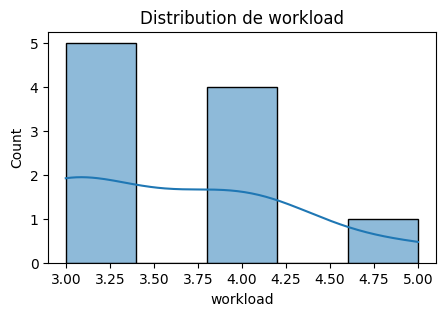

Test de normalité pour difficulty:
Statistique: 0.7559678554534912, p-value: 0.0042188530787825584
La distribution n'est pas normale.


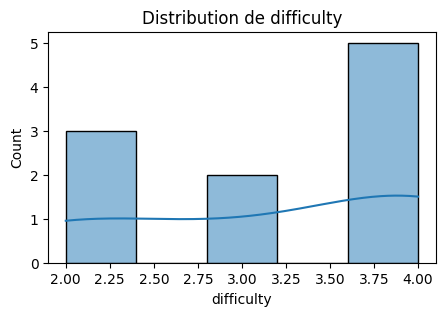

Test de normalité pour complexity:
Statistique: 0.780940055847168, p-value: 0.00849983375519514
La distribution n'est pas normale.


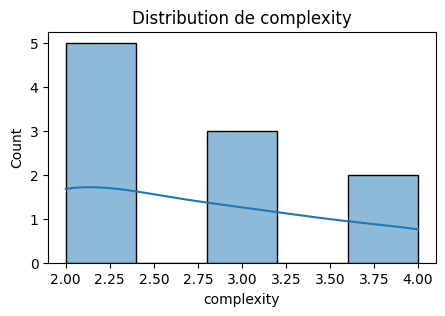

Test de normalité pour mental.demand:
Statistique: 0.7964456081390381, p-value: 0.013125520199537277
La distribution n'est pas normale.


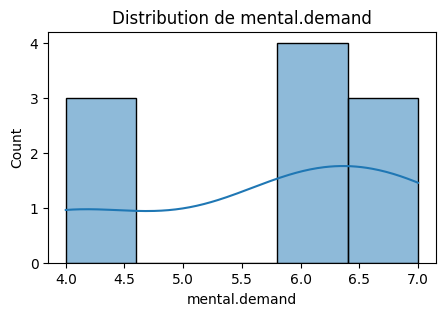

Test de normalité pour physical.demand:
Statistique: 0.9238799810409546, p-value: 0.39045506715774536
La distribution est normale.


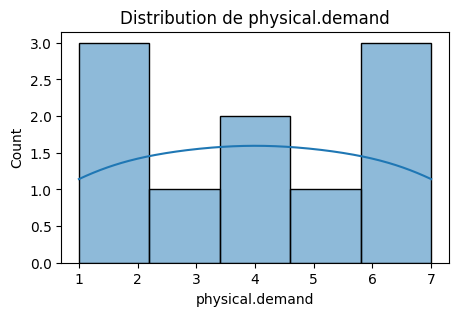

Test de normalité pour temporal.demand:
Statistique: 0.8760036826133728, p-value: 0.1173669621348381
La distribution est normale.


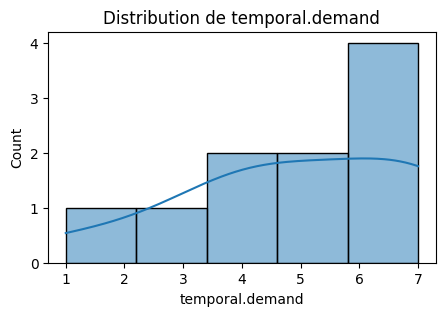

Test de normalité pour performance:
Statistique: 0.782243013381958, p-value: 0.00881610531359911
La distribution n'est pas normale.


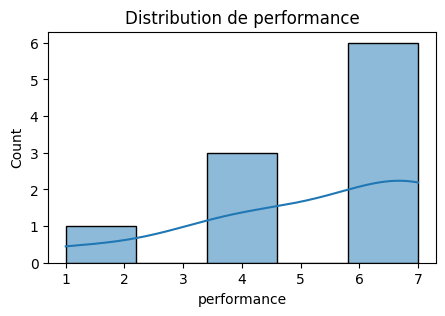

Test de normalité pour effort:
Statistique: 0.901607871055603, p-value: 0.2281642109155655
La distribution est normale.


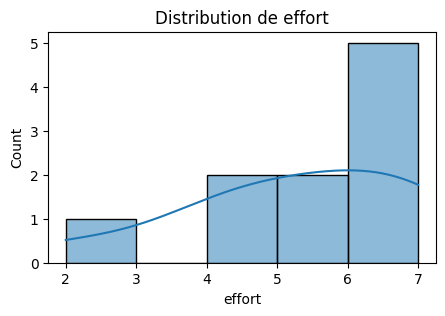

Test de normalité pour frustration:
Statistique: 0.7896729111671448, p-value: 0.010857435874640942
La distribution n'est pas normale.


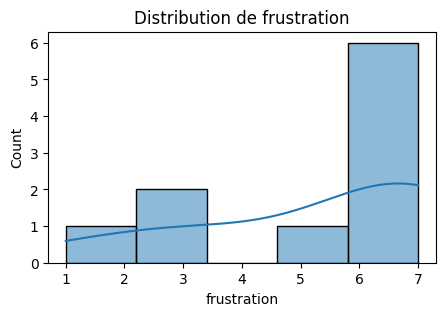

In [ ]:
from scipy import stats
# Test de normalité pour chaque variable
for column in data.columns:
    if column not in ['group']:
        print(f"Test de normalité pour {column}:")
        stat, p = stats.shapiro(data[column])
        print(f"Statistique: {stat}, p-value: {p}")
        if p > 0.05:
            print("La distribution est normale.")
        else:
            print("La distribution n'est pas normale.")
        plt.figure(figsize=(5, 3))
        sns.histplot(data[column], kde=True)
        plt.title(f"Distribution de {column}")
        plt.show()

II. 7. Visualisation de la distribution par des boites à moustaches

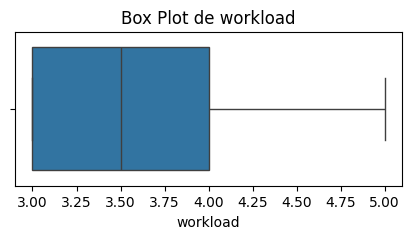

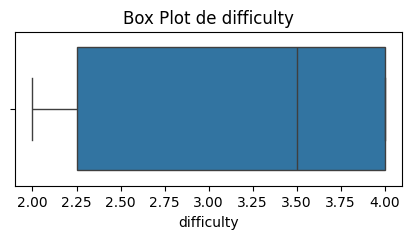

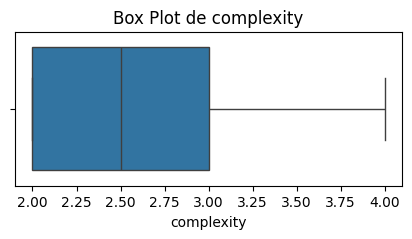

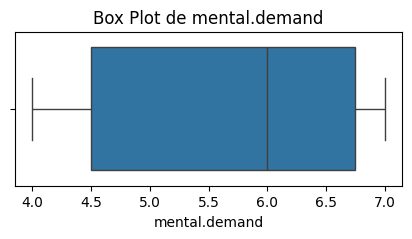

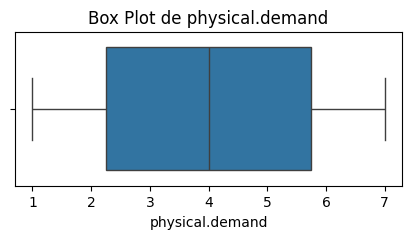

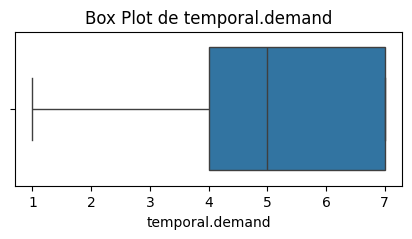

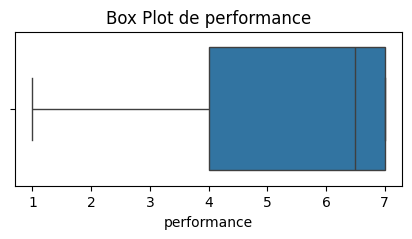

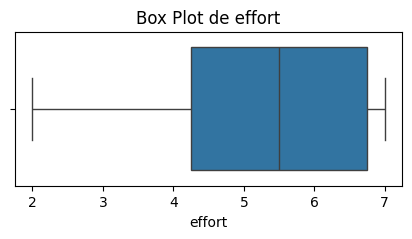

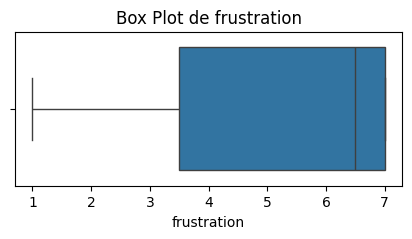

In [ ]:
# Box Plots
for column in data.columns:
    if column not in ['group']:
      plt.figure(figsize=(5, 2))
      sns.boxplot(x=data[column])
      plt.title(f"Box Plot de {column}")
      plt.show()

II. 8. Tests statistiques appropriés : Test t de Student et test de Mann-Whitney

In [ ]:
from scipy.stats import ttest_ind, mannwhitneyu

# Séparer les données par groupe
group_0 = data[data['group'] == 0]
group_1 = data[data['group'] == 1]

# Test de student pour "physical.demand",	"temporal.demand",	"effort"
for column in ["physical.demand",	"temporal.demand",	"effort"]:
    stat, p = ttest_ind(group_0[column], group_1[column])
    print("\nTest statistique t de Student pour :")
    print(f"{column}: stat={stat}, p={p}")
    if p < 0.05:
        print(f"Il y a une différence significative entre les groupes pour {column}.")
    else:
        print(f"Il n'y a pas de différence significative entre les groupes pour {column}.")

# Test de Mann-Whitney pour  "workload", "difficulty", "complexity",	"mental.demand", "performance", "frustration"
for column in [ "workload", "difficulty", "complexity",	"mental.demand", "performance", "frustration"]:
    stat, p = mannwhitneyu(group_0[column], group_1[column])
    print("\nTest statistique de Mann-Whitney pour :")
    print(f"{column} (Mann-Whitney): stat={stat}, p={p}")
    if p < 0.05:
        print(f"Il y a une différence significative entre les groupes pour {column}.")
    else:
        print(f"Il n'y a pas de différence significative entre les groupes pour {column}.")



Test statistique t de Student pour :
physical.demand: stat=-0.5369248441712197, p=0.605925744308935
Il n'y a pas de différence significative entre les groupes pour physical.demand.

Test statistique t de Student pour :
temporal.demand: stat=0.5929994533288815, p=0.5695613951781363
Il n'y a pas de différence significative entre les groupes pour temporal.demand.

Test statistique t de Student pour :
effort: stat=-0.9622504486493761, p=0.3641028550510263
Il n'y a pas de différence significative entre les groupes pour effort.

Test statistique de Mann-Whitney pour :
workload (Mann-Whitney): stat=16.0, p=0.4884223166225936
Il n'y a pas de différence significative entre les groupes pour workload.

Test statistique de Mann-Whitney pour :
difficulty (Mann-Whitney): stat=13.0, p=1.0
Il n'y a pas de différence significative entre les groupes pour difficulty.

Test statistique de Mann-Whitney pour :
complexity (Mann-Whitney): stat=21.0, p=0.06964240479832813
Il n'y a pas de différence significat

II. 9. Statistiques de base pour chaque groupe

In [ ]:
group_0 = data[data['group'] == 0]
group_1 = data[data['group'] == 1]

# Analyse descriptive pour le groupe 0
print("Analyse descriptive pour le groupe 0 :")
print(group_0.describe())

Analyse descriptive pour le groupe 0 :
       group  workload  difficulty  complexity  mental.demand  \
count    5.0   5.00000    5.000000     5.00000       5.000000   
mean     0.0   3.80000    3.200000     3.20000       5.400000   
std      0.0   0.83666    1.095445     0.83666       1.341641   
min      0.0   3.00000    2.000000     2.00000       4.000000   
25%      0.0   3.00000    2.000000     3.00000       4.000000   
50%      0.0   4.00000    4.000000     3.00000       6.000000   
75%      0.0   4.00000    4.000000     4.00000       6.000000   
max      0.0   5.00000    4.000000     4.00000       7.000000   

       physical.demand  temporal.demand  performance    effort  frustration  
count         5.000000         5.000000     5.000000  5.000000          5.0  
mean          3.600000         5.400000     5.200000  4.800000          5.0  
std           2.607681         1.516575     2.683282  1.923538          2.0  
min           1.000000         4.000000     1.000000  2.000000 

In [ ]:
# Analyse descriptive pour le groupe 1
print("Analyse descriptive pour le groupe 1 :")
print(group_1.describe())

Analyse descriptive pour le groupe 1 :
       group  workload  difficulty  complexity  mental.demand  \
count    5.0  5.000000     5.00000    5.000000       5.000000   
mean     1.0  3.400000     3.20000    2.200000       6.000000   
std      0.0  0.547723     0.83666    0.447214       1.224745   
min      1.0  3.000000     2.00000    2.000000       4.000000   
25%      1.0  3.000000     3.00000    2.000000       6.000000   
50%      1.0  3.000000     3.00000    2.000000       6.000000   
75%      1.0  4.000000     4.00000    2.000000       7.000000   
max      1.0  4.000000     4.00000    3.000000       7.000000   

       physical.demand  temporal.demand  performance   effort  frustration  
count         5.000000         5.000000     5.000000  5.00000     5.000000  
mean          4.400000         4.600000     5.600000  5.80000     5.600000  
std           2.073644         2.607681     1.516575  1.30384     2.607681  
min           2.000000         1.000000     4.000000  4.00000     1